# Эксперименты с ABM «Отказ НПЗ и дефицит бензина» (refinery_shock_abm, NetLogo 7)

Общий ноутбук проекта. Этапы добавляются по очереди; каждый этап читает файлы предыдущего из `OUT_DIR`, поэтому ноутбук можно перезапускать с любого этапа.

| Этап | Что делаем | Главные файлы |
|---|---|---|
| **0. Подготовка** (этот блок) | проверки модели, seed, горизонт, время прогона, число повторов R, выбор плана скрининга, базовый прогон P0 | `seeds.json`, `factors.csv`, `pilot.csv`, `baseline_P0.csv`, `prep_summary.json` |
| 1. Скрининг | факториальный план по переключателям L2–L6 × 3 уровня `shock-depth` × R повторов (CRN), ANOVA, эффекты | `design_screening.csv`, `screening.csv` |
| 2. Оптимизация уровней | LHS по непрерывным параметрам оставшихся рычагов, отбор финалистов | `design_levels.csv`, `levels.csv` |
| 3. Устойчивость | финалисты × LHS неопределённости × `shock-depth` × повторы; среднее, худший случай, сожаление, чувствительность (PRCC) | `design_robust.csv`, `robust.csv` |
| 4. Постобработка | Парето-фронт, таблица «сценарий приоритетов → стратегия», карта весов | рисунки, таблицы |
| 5. Проверка | финалисты на новых seed | `validation.csv` |

**Как работает запуск.** Модуль `abm_runner.py` (создаётся ячейкой ниже) держит по одной JVM с загруженной моделью в каждом процессе. Перед каждым прогоном выставляются *все* элементы интерфейса (`clear-all` их не сбрасывает), затем `setup`, затем, если нужно, переопределение констант неопределённости, затем `repeat N [go]`. KPI читаются одним вызовом в контрольных точках (по умолчанию дни 30, 90, 180 и 365).

## 0.1. Окружение

Нужны NetLogo 7 (установленный, лицензия не нужна) и пакеты Python. Java отдельно ставить не нужно: используется JVM, встроенная в NetLogo (папка `runtime`).

In [1]:
import json, hashlib, math, os, platform, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=C)})

## 0.2. Конфигурация

**Единственная ячейка, которую нужно править под свой компьютер:** пути к NetLogo и к модели. Остальное - решения по дизайну эксперимента (обоснование в комментариях; диапазоны - предложение, их нужно подтвердить источниками в отчёте).

In [2]:
# --- пути (Windows: r"C:\Program Files\NetLogo 7.0.3") ---
NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path(r"refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")
OUT_DIR.mkdir(exist_ok=True)

# --- время ---
HORIZON     = 365                      # дней (1 tick = 1 день), шок с 5-го дня
CHECKPOINTS = [30, 90, 180, HORIZON]   # дни, в которые снимаем накопленные KPI (фаза кризиса vs год)

# --- сценарная ось ---
# Поражённый НПЗ даёт ~1/3 рынка, поэтому потеря рынка ~ shock-depth / 3.
# Экспортный буфер normal-surplus = 6%: L2 закрывает потерю до ~6% рынка (shock-depth ~ 0.18).
# 0.2 -> ~6.7% (почти закрывается L2), 0.45 -> ~15%, 0.7 -> ~23% (без L3/L4 дефицит неизбежен)
SHOCK_LEVELS = [0.2, 0.45, 0.7]
SHOCK_MID    = 0.45

# --- рычаги ЛПР ---
LEVERS = {  # короткое имя -> переключатель интерфейса
    "L2": "L2-export-ban?", "L3": "L3-quality-relax?", "L4": "L4-import?",
    "L5": "L5-fillup-limit?", "L6": "L6-price-cap?",
}
LEVER_RANGES = {  # для этапа 2 (LHS по силе рычагов); 'off' эквивалентен краю диапазона
    "L3-share-naphtha":     (0.0, 0.5),    # 0 = L3 выключен
    "L4-import-limit":      (0.0, 0.3),    # 0 = L4 выключен (доля D0 в день)
    "L5-liters-per-fillup": (10, 70),      # >= 70 (бак 50 + канистра 20) = L5 не действует
    "L6-price-cap":         (1.0, 2.0),
}
LEVER_ON = None   # уровни 'on' для скрининга; None = значения слайдеров из файла модели
# L4-subsidy НЕ влияет на динамику (объём импорта от неё не зависит): K2 = L4-subsidy * объём импорта.
# Поэтому субсидию держим на значении из модели, а K2 при другой субсидии пересчитываем без прогонов.

# --- неопределённость (этап 3, LHS); номинал = константа модели ---
UNC_RANGES = {
    "panic-sensitivity": (0.5, 2.0),     # номинал 1.0
    "tau-down":          (7, 30),        # номинал 14 дней
    "w-own-experience":  (0.2, 0.8),     # номинал 0.5
    "price-elasticity":  (-0.4, -0.05),  # номинал -0.2; краткосрочная эластичность бензина
    "normal-surplus":    (0.02, 0.12),   # номинал 0.06
}
C3_RANGE = (0.05, 0.5)   # ущерб от низкосортного бензина, m.u./L; только постобработка: K3-cost = c3 * ref-price * K3-volume

# --- воспроизводимость ---

MASTER_SEED = 20261119   
SEED_POOLS  = {"diag": 10, "pilot": 30, "screening": 50, "levels": 30, "robust": 30, "validation": 50}

# --- вычисления ---
N_WORKERS_MAX = max(1, (os.cpu_count() or 2) - 1)
JVM_ARGS      = ["-Xmx1g"]      # память на одну JVM (по процессу)

KPIS     = ["K0", "K1", "K2", "K3_volume", "K4", "K5_hours"]
KPI_NAME = {"K0": "физический дефицит, L", "K1": "спрос, вытесненный ценой, L",
            "K2": "субсидия импорта, m.u.", "K3_volume": "низкосортный бензин, L",
            "K4": "переплата потребителей, m.u.", "K5_hours": "очереди, машино-часы"}

## 0.4. Подключение к NetLogo и паспорт модели

Читаем из модели значения слайдеров (уровни рычагов по умолчанию) и все константы после `setup`. SHA-256 файла модели фиксирует версию: если файл изменится, результаты разных этапов нельзя смешивать.

In [3]:
import importlib
import abm_runner as ar

importlib.reload(ar) 

<module 'abm_runner' from 'c:\\Users\\arsmi\\Downloads\\netlogo-project\\Experiments\\abm_runner.py'>

In [4]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

MODEL_SHA256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
BASE_CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()),
            "jvmargs": JVM_ARGS, "jvm_path": ar.find_jvm(NETLOGO_HOME),
            "horizon": HORIZON, "checkpoints": CHECKPOINTS}
print("JVM:", BASE_CFG["jvm_path"])

link = ar.make_link(BASE_CFG)          # JVM в процессе ноутбука (для диагностики и n_workers = 1)
NETLOGO_VERSION = link.report("netlogo-version")
print("NetLogo", NETLOGO_VERSION, "| модель sha256:", MODEL_SHA256[:16], "...")

slider_vals = dict(zip(ar.SLIDERS, np.atleast_1d(link.report(ar.nl_list(ar.SLIDERS))).tolist()))
INTERFACE_DEFAULTS = {sw: False for sw in ar.SWITCHES} | slider_vals   # P0: все переключатели off
INTERFACE_DEFAULTS["shock-depth"] = SHOCK_MID
if LEVER_ON is None:
    LEVER_ON = {k: slider_vals[k] for k in LEVER_RANGES}
print("Слайдеры в файле модели:", slider_vals)
print("Уровни 'on' для скрининга:", LEVER_ON)

# константы после setup (seed любой - от него зависит только policy-delay)
link.command(" ".join(f"set {k} {ar.nl_value(v)}" for k, v in INTERFACE_DEFAULTS.items()) + " set seed 1 setup")
CONSTANTS = dict(zip(ar.CONSTANT_REPORTERS,
                     np.atleast_1d(link.report(ar.nl_list(ar.CONSTANT_REPORTERS))).tolist()))
NOMINAL_UNC = {k: CONSTANTS[k] for k in ar.UNCERTAIN}
print("Номинал неопределённых параметров:", NOMINAL_UNC)

CFG = BASE_CFG | {"interface_defaults": INTERFACE_DEFAULTS, "nominal_uncertain": NOMINAL_UNC}
pd.Series(CONSTANTS, name="значение").to_frame()

JVM: C:\Program Files\NetLogo 7.0.4\runtime\bin\server\jvm.dll
NetLogo 7.0.4 | модель sha256: 2b246166dc0c1182 ...
Слайдеры в файле модели: {'L3-share-naphtha': 0.15, 'L4-import-limit': 0.1, 'L4-subsidy': 0.25, 'L5-liters-per-fillup': 30.0, 'L6-price-cap': 1.1, 'shock-depth': 0.5}
Уровни 'on' для скрининга: {'L3-share-naphtha': 0.15, 'L4-import-limit': 0.1, 'L5-liters-per-fillup': 30.0, 'L6-price-cap': 1.1}
Номинал неопределённых параметров: {'panic-sensitivity': 1.0, 'tau-down': 14.0, 'w-own-experience': 0.5, 'price-elasticity': -0.2, 'normal-surplus': 0.06}


,значение
shock-start,5.000000
policy-delay,8.000000
L3-ramp-days,7.000000
L4-import-delay,14.000000
n-refineries,3.000000
n-stations,40.000000
n-consumers,5000.000000
normal-surplus,0.060000
naphtha-ratio,0.600000
refinery-storage-days,7.000000


### Таблица факторов

Фиксируется до экспериментов и идёт в отчёт (раздел Experimental design). Роли: **рычаг** - выбирает регулятор; **сценарий** - внешняя ось, по которой результаты показываются отдельно; **неопределённость** - параметры, к которым стратегия должна быть устойчива; **постобработка** - не влияют на динамику, пересчитываются по готовым прогонам.

In [5]:
rows = [{"фактор": sw, "роль": "рычаг (on/off)", "номинал": "off", "диапазон / уровни": "off / on",
         "этапы": "1-5"} for sw in ar.SWITCHES]
rows += [{"фактор": k, "роль": "рычаг (сила)", "номинал": LEVER_ON[k], "диапазон / уровни": f"{lo} ... {hi}",
          "этапы": "2-5 (в 1 - уровень 'on')"} for k, (lo, hi) in LEVER_RANGES.items()]
rows += [{"фактор": "shock-depth", "роль": "сценарий", "номинал": SHOCK_MID,
          "диапазон / уровни": " / ".join(map(str, SHOCK_LEVELS)), "этапы": "все"}]
rows += [{"фактор": k, "роль": "неопределённость", "номинал": NOMINAL_UNC[k],
          "диапазон / уровни": f"{lo} ... {hi} (LHS)", "этапы": "3, 5"} for k, (lo, hi) in UNC_RANGES.items()]
rows += [{"фактор": "c3", "роль": "неопределённость (постобработка)", "номинал": "-",
          "диапазон / уровни": f"{C3_RANGE[0]} ... {C3_RANGE[1]}", "этапы": "3-5, без прогонов"},
         {"фактор": "L4-subsidy", "роль": "рычаг (постобработка)", "номинал": slider_vals["L4-subsidy"],
          "диапазон / уровни": "K2 = L4-subsidy x объём импорта", "этапы": "4"},
         {"фактор": "policy-delay", "роль": "внутренний шум (из seed)", "номинал": "7-10 дней",
          "диапазон / уровни": "random 4 в setup", "этапы": "все"}]
FACTORS = pd.DataFrame(rows)
FACTORS.to_csv(OUT_DIR / "factors.csv", index=False, encoding="utf-8-sig")
FACTORS

,фактор,роль,номинал,диапазон / уровни,этапы
0,L2-export-ban?,рычаг (on/off),off,off / on,1-5
1,L3-quality-relax?,рычаг (on/off),off,off / on,1-5
2,L4-import?,рычаг (on/off),off,off / on,1-5
3,L5-fillup-limit?,рычаг (on/off),off,off / on,1-5
4,L6-price-cap?,рычаг (on/off),off,off / on,1-5
5,L3-share-naphtha,рычаг (сила),0.15,0.0 ... 0.5,2-5 (в 1 - уровень 'on')
6,L4-import-limit,рычаг (сила),0.1,0.0 ... 0.3,2-5 (в 1 - уровень 'on')
7,L5-liters-per-fillup,рычаг (сила),30.0,10 ... 70,2-5 (в 1 - уровень 'on')
8,L6-price-cap,рычаг (сила),1.1,1.0 ... 2.0,2-5 (в 1 - уровень 'on')
9,shock-depth,сценарий,0.45,0.2 / 0.45 / 0.7,все


## 1. Наборы seed

Все seed берутся из одного генератора `MASTER_SEED` и делятся на **непересекающиеся** пулы: проверка на этапе 5 идёт на seed, которых модель «не видела». Внутри этапа все комбинации рычагов используют одни и те же seed (общие случайные числа, CRN): повтор r = seed r. Слайдер `seed` в модели 0-1000, `seed = 0` означает случайное зерно, поэтому берём 1-1000.

CRN в ABM частичные: `setup` (город, машины, `policy-delay`) у всех стратегий одинаков, но после шока разные стратегии тратят разное количество случайных чисел, и потоки расходятся. Насколько CRN всё-таки уменьшает дисперсию разниц, видно в пилоте (раздел 4).

In [6]:
_rng = np.random.default_rng(MASTER_SEED)
_perm = _rng.permutation(np.arange(1, 1001)).tolist()
SEEDS, i = {}, 0
for name, n in SEED_POOLS.items():
    SEEDS[name] = _perm[i:i + n]
    i += n
assert len(set(sum(SEEDS.values(), []))) == i, "пулы пересекаются"
(OUT_DIR / "seeds.json").write_text(json.dumps({"master_seed": MASTER_SEED, "pools": SEEDS}, indent=1))
{k: v[:5] for k, v in SEEDS.items()}

{'diag': [619, 16, 466, 973, 778],
 'pilot': [392, 334, 8, 972, 568],
 'screening': [347, 164, 159, 797, 98],
 'levels': [591, 763, 194, 329, 233],
 'robust': [611, 262, 984, 657, 156],
 'validation': [379, 840, 676, 490, 279]}

In [7]:
# Политики для проверок и пилота (P1, P2 - пакеты из постановки)
def policy(*levers, **strength):
    p = {LEVERS[l]: True for l in levers}
    p.update(LEVER_ON)
    p.update(strength)
    return p

POLICIES = {"P0": policy(), "P1": policy("L3", "L5", "L6"), "P2": policy("L2", "L4"),
            "ALL": policy("L2", "L3", "L4", "L5", "L6")}

def job(seed, pol="P0", shock=SHOCK_MID, unc=None, stage="diag", design_id=None, tag=None, **labels):
    # pol: имя из POLICIES или dict параметров интерфейса (тогда нужен design_id)
    if isinstance(pol, str):
        params, design_id = POLICIES[pol] | {"shock-depth": shock}, pol
    else:
        params = pol | {"shock-depth": shock}
    run_id = f"{stage}|{design_id}|sd={shock}|seed={seed}" + (f"|{tag}" if tag else "")
    return {"run_id": run_id, "stage": stage, "design_id": design_id, "shock": shock, "seed": int(seed),
            "params": params, "uncertain": unc, **labels}

CHECKS = {}
def check(name, ok, detail=""):
    CHECKS[name] = {"ok": bool(ok), "detail": str(detail)}
    print(("PASS " if ok else "FAIL ") + name + (f" | {detail}" if detail else ""))

## 2. Проверки модели

Модель замораживается после этих проверок. Проверки C1 и C5 повторяют приёмочные проверки модели, но уже в связке Python-NetLogo, на которой будут идти все эксперименты.

### 2.1. Воспроизводимость (C5) и невмешательство чтения

Один seed дважды подряд должен дать побитово одинаковые KPI. Ежедневное чтение состояния (`run_timeseries`) не должно менять траекторию: все репортёры модели обёрнуты в `with-local-randomness`.

In [8]:
# s = SEEDS["diag"][0]
# j = job(s, "ALL")
# a, b = ar.run_one(link, j, CFG), ar.run_one(link, j, CFG)
# ts = ar.run_timeseries(link, j, CFG)
# same = all(a[k] == b[k] for k in KPIS)
# check("C5: тот же seed -> те же KPI", same, {k: a[k] for k in KPIS})
# same_ts = all(np.isclose(ts.iloc[-1][r], a[k], rtol=0, atol=0)
#               for k, r in [("K0", "K0-total"), ("K4", "K4-total"), ("K5_hours", "K5-total-hours")])
# check("чтение каждый день не меняет траекторию", same_ts)
# print(f"один прогон {HORIZON} дней: {a['sec']:.1f} с")

### 2.2. Переопределение констант неопределённости

(a) Номинальные значения через `override_command` дают тот же прогон, что и без переопределения (побитово).
(b) `panic-sensitivity` масштабирует `panic-i`; `normal-surplus` масштабирует мощность НПЗ, а случайный поток не сдвигается (`policy-delay` и город те же).
(c) Направление эффектов разумно: сильнее паника -> больше дефицит; больше `normal-surplus` -> меньше дефицит при P0.

In [9]:
# s = SEEDS["diag"][1]
# base = ar.run_one(link, job(s, "P0"), CFG)
# nom = ar.run_one(link, job(s, "P0", unc=dict(NOMINAL_UNC), tag="nominal"), CFG)
# check("(a) оверрайд номиналом = без оверрайда", all(base[k] == nom[k] for k in KPIS))

# def probe(unc):
#     j = job(s, "P0", unc=unc, tag="probe")
#     ar._prepare(link, j, CFG)
#     r = link.report("(list mean [panic-i] of consumers  sum [capacity] of refineries  policy-delay  "
#                     "[xcor] of min-one-of consumers [who])")
#     return np.atleast_1d(r).tolist()

# p0 = probe(None)
# p1 = probe({"panic-sensitivity": 2.0, "normal-surplus": 0.12})
# check("(b) panic-i x2", math.isclose(p1[0] / p0[0], 2.0 / NOMINAL_UNC["panic-sensitivity"], rel_tol=1e-9),
#       f"{p0[0]:.4f} -> {p1[0]:.4f}")
# check("(b) capacity x (1.12/1.06)", math.isclose(p1[1] / p0[1], 1.12 / (1 + NOMINAL_UNC["normal-surplus"]), rel_tol=1e-9))
# check("(b) случайный поток не сдвинут (policy-delay, координаты)", p0[2] == p1[2] and p0[3] == p1[3])

# lo = ar.run_one(link, job(s, "P0", unc={"panic-sensitivity": 0.5}, tag="lo"), CFG)
# hi = ar.run_one(link, job(s, "P0", unc={"panic-sensitivity": 2.0}, tag="hi"), CFG)
# check("(c) паника 2.0 даёт больший K0, чем 0.5", hi["K0"] > lo["K0"], f"{lo['K0']:.0f} vs {hi['K0']:.0f}")
# # normal-surplus при P0 почти не меняет внутреннее предложение (излишек и так уходит на экспорт),
# # он работает через L2: запрет экспорта освобождает больше. Поэтому проверяем на политике «только L2».
# l2 = policy("L2")
# ns_lo = ar.run_one(link, job(s, l2, design_id="L2", unc={"normal-surplus": 0.02}, tag="ns_lo"), CFG)
# ns_hi = ar.run_one(link, job(s, l2, design_id="L2", unc={"normal-surplus": 0.12}, tag="ns_hi"), CFG)
# check("(c) при L2: normal-surplus 0.12 даёт меньший K0, чем 0.02", ns_hi["K0"] < ns_lo["K0"],
#       f"{ns_lo['K0']:.0f} vs {ns_hi['K0']:.0f}")

### 2.3. Норма без шока (C1)

`shock-depth = 0`, все меры выключены: цена 1 ± 0.03 после 20-го дня, дефицита нет, доля пустых АЗС < 5%.

FAIL C1: цена 1 +- 0.03 после 20-го дня | min 0.980, max 1.035
PASS C1: K0 ~ 0 | K0 = 0.0 L
FAIL C1: dry-share < 0.05 | max 0.100


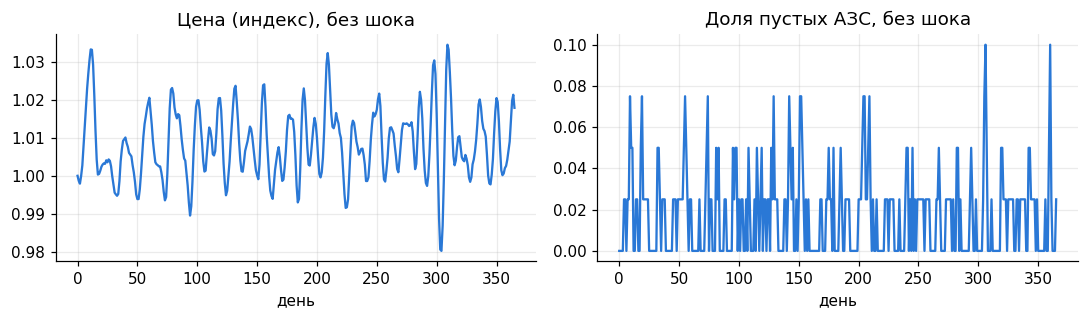

In [25]:
ts0 = ar.run_timeseries(link, job(SEEDS["diag"][2], "P0", shock=0.0), CFG)
after = ts0[ts0.ticks >= 20]
check("C1: цена 1 +- 0.03 после 20-го дня", after.price.between(0.97, 1.03).all(),
      f"min {after.price.min():.3f}, max {after.price.max():.3f}")
check("C1: K0 ~ 0", ts0["K0-total"].iloc[-1] < 1e-6 * CONSTANTS["D0"] * HORIZON, f"K0 = {ts0['K0-total'].iloc[-1]:.1f} L")
check("C1: dry-share < 0.05", ts0["dry-share"].max() < 0.05, f"max {ts0['dry-share'].max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ts0.ticks, ts0.price); ax[0].set_title("Цена (индекс), без шока"); ax[0].set_xlabel("день")
ax[1].plot(ts0.ticks, ts0["dry-share"]); ax[1].set_title("Доля пустых АЗС, без шока"); ax[1].set_xlabel("день")
plt.tight_layout(); plt.show()

### 2.4. Баланс массы

Для прогона с шоком и всеми мерами: изменение суммарных запасов (НПЗ + в пути + АЗС + машины) за день равно производство − экспорт + импорт − фактическое потребление (потребление − K0 за день). Остаток должен быть на уровне ошибки округления.

In [11]:
# tsb = ar.run_timeseries(link, job(SEEDS["diag"][3], "ALL", shock=SHOCK_LEVELS[-1]), CFG)
# stock = tsb[["total-refinery-stock", "total-pipeline-stock", "total-station-stock", "total-consumer-stock"]].sum(axis=1)
# flow = (tsb["production-today"] - tsb["export-today"] + tsb["import-today"]
#         - (tsb["consumption-today"] - tsb["K0-today"]))
# resid = (stock.diff() - flow).iloc[1:]
# rel = resid.abs().max() / CONSTANTS["D0"]
# check("баланс массы", rel < 1e-6, f"max |остаток| = {resid.abs().max():.2e} L ({rel:.1e} D0)")

### 2.5. Горизонт: что накапливается за 365 дней

Шок постоянный, поэтому за год накопленные KPI в основном отражают **новый устойчивый режим**, а не острую фазу паники. Таблица показывает, какая доля годового значения набирается к 30/90/180-му дню. Если острая фаза важна для выводов, на этапах анализа используем и KPI на день 90 (они уже пишутся в контрольных точках, столбцы `K0@90` и т. д.).

In [ ]:
diag = {}
for shock in SHOCK_LEVELS:
    for pol in ["P0", "ALL"]:
        diag[(shock, pol)] = ar.run_timeseries(link, job(SEEDS["diag"][4], pol, shock=shock), CFG)

fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for col, shock in enumerate(SHOCK_LEVELS):
    for i, pol in enumerate(["P0", "ALL"]):
        d = diag[(shock, pol)]
        axes[0, col].plot(d.ticks, d.price, color=C[i], label=pol)
        axes[1, col].plot(d.ticks, d["dry-share"], color=C[i], label=pol)
        axes[2, col].plot(d.ticks, d["K0-today"] / CONSTANTS["D0"], color=C[i], label=pol)
    axes[0, col].set_title(f"shock-depth = {shock}")
axes[0, 0].set_ylabel("цена (индекс)"); axes[1, 0].set_ylabel("доля пустых АЗС")
axes[2, 0].set_ylabel("дефицит за день / D0")
for a in axes[2]: a.set_xlabel("день")
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

rows = []
for (shock, pol), d in diag.items():
    r = {"shock": shock, "policy": pol}
    for k, col in [("K0", "K0-total"), ("K4", "K4-total"), ("K5", "K5-total-hours")]:
        tot = d[col].iloc[-1]
        for cp in CHECKPOINTS[:-1]:
            r[f"{k}: доля к дню {cp}"] = d[col].iloc[cp] / tot if tot > 0 else np.nan
    rows.append(r)
pd.DataFrame(rows).round(2)

In [ ]:
# Фон без шока (C1) и абсолютные KPI для таблицы горизонта
d = ts0[ts0.ticks >= 20]
print(f"цена без шока: среднее {d.price.mean():.3f}, sd {d.price.std():.3f}, "
      f"дней вне 1 +- 0.03: {(~d.price.between(0.97, 1.03)).sum()} из {len(d)}")
print(f"dry-share без шока: среднее {d['dry-share'].mean():.3f}, "
      f"дней > 0.05: {(d['dry-share'] > 0.05).sum()} из {len(d)}")
print("фон за год без шока:", {k: round(ts0[c].iloc[-1]) for k, c in
      [("K1", "K1-total"), ("K4", "K4-total"), ("K5", "K5-total-hours")]})

D0 = CONSTANTS["D0"]
rows = []
for (shock, pol), x in diag.items():
    rows.append({"shock": shock, "policy": pol,
                 "K0 (дней спроса D0)": x["K0-total"].iloc[-1] / D0,
                 "K1 (дней D0)": x["K1-total"].iloc[-1] / D0,
                 "K4, m.u.": x["K4-total"].iloc[-1],
                 "K5, ч/машину": x["K5-total-hours"].iloc[-1] / CONSTANTS["n-consumers"],
                 "цена к концу года": x["price"].iloc[-1]})
pd.DataFrame(rows).round(2)

## 3. Время прогона и параллельность

Меряем время одного прогона в процессе ноутбука и пропускную способность пула при разном числе процессов (в каждом своя JVM, старт JVM и загрузка модели входят в замер). Дальше бюджет всех этапов считается по лучшей пропускной способности.

In [13]:
import importlib.util
print("tqdm:", importlib.util.find_spec("tqdm") is not None,
      "| ipywidgets:", importlib.util.find_spec("ipywidgets") is not None)
print("логических ядер:", os.cpu_count())
try:
    import psutil
    vm = psutil.virtual_memory()
    print("физических ядер:", psutil.cpu_count(logical=False),
          f"| RAM {vm.total / 2**30:.1f} ГБ, свободно {vm.available / 2**30:.1f} ГБ")
except ImportError:
    print("psutil нет (%pip install psutil): ядра и память посмотрите в Диспетчере задач")

tqdm: True | ipywidgets: True
логических ядер: 8
физических ядер: 4 | RAM 15.8 ГБ, свободно 1.8 ГБ


In [14]:
import traceback
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED
from multiprocessing import get_context

def log(msg):
    print(time.strftime("%H:%M:%S"), msg, flush=True)

def _meta(j):
    return {k: v for k, v in j.items() if k not in ("params", "uncertain")}

def run_batch_logged(jobs, cfg, n_workers=1, out_csv=None, resume=True, link=None,
                     flush_every=50, progress=True, heartbeat_sec=30, stall_min=10):
    out_csv = Path(out_csv) if out_csv else None
    done_df = None
    if out_csv is not None and resume and out_csv.exists():
        done_df = pd.read_csv(out_csv)
        if "error" in done_df:
            done_df = done_df[done_df["error"].isna()]
        done_ids = set(done_df["run_id"])
        jobs = [j for j in jobs if j["run_id"] not in done_ids]
        log(f"уже посчитано {len(done_ids)}, осталось {len(jobs)}")
    if len({j["run_id"] for j in jobs}) != len(jobs):
        raise ValueError("run_id не уникальны")

    results, buffer, n_err = [], [], 0
    t0 = time.perf_counter()
    last_report = t0

    def flush():
        nonlocal buffer
        if out_csv is not None and buffer:
            parts = ([done_df] if done_df is not None and len(done_df) else []) + [pd.DataFrame(results)]
            tmp = out_csv.with_suffix(".tmp")
            pd.concat(parts, ignore_index=True).to_csv(tmp, index=False)
            os.replace(tmp, out_csv)
        buffer = []

    def add(r):
        nonlocal last_report, n_err
        results.append(r); buffer.append(r)
        if len(buffer) >= flush_every:
            flush()
        if r.get("error"):
            n_err += 1
            if n_err <= 3:
                log(f"ОШИБКА {r.get('run_id')}:\n{r['error'][-1500:]}")
        now = time.perf_counter()
        if progress and (now - last_report >= heartbeat_sec or len(results) == len(jobs)):
            k, el = len(results), now - t0
            log(f"{k}/{len(jobs)} готово | прошло {el / 60:.1f} мин | осталось ~{el / k * (len(jobs) - k) / 60:.1f} мин")
            last_report = now

    if n_workers <= 1:
        if link is None:
            raise ValueError("для n_workers = 1 нужен link")
        log(f"{len(jobs)} прогонов в процессе ноутбука")
        for j in jobs:
            try:
                r = ar.run_one(link, j, cfg)
            except Exception:
                r = {**_meta(j), "error": traceback.format_exc()}
            add(r)
    elif jobs:
        log(f"пул: {n_workers} процессов, {len(jobs)} прогонов. Первый результат - после запуска Java и одного прогона")
        ex = ProcessPoolExecutor(max_workers=n_workers, mp_context=get_context("spawn"),
                                 initializer=ar._init_worker, initargs=(cfg,))
        pending = {ex.submit(ar._worker_task, j): j for j in jobs}
        idle_since, stalled = time.perf_counter(), False
        try:
            while pending:
                done, _ = wait(list(pending), timeout=heartbeat_sec, return_when=FIRST_COMPLETED)
                if not done:
                    idle = (time.perf_counter() - idle_since) / 60
                    log(f"... работаю: {len(results)}/{len(jobs)}, новых результатов нет {idle:.1f} мин")
                    if idle > stall_min:
                        log("нет результатов дольше stall_min - останавливаю пул (проверьте окна Java на панели задач)")
                        stalled = True
                        break
                    continue
                idle_since = time.perf_counter()
                for f in done:
                    j = pending.pop(f)
                    try:
                        r = f.result()
                    except Exception:            # процесс упал (например, не стартовала JVM)
                        r = {**_meta(j), "error": traceback.format_exc()}
                    add(r)
        finally:
            # процесс с JVM сам не завершается (JPype ждёт потоки NetLogo) - завершаем принудительно
            for p in list(getattr(ex, "_processes", {}).values()):
                p.terminate()
            ex.shutdown(wait=False, cancel_futures=True)
    flush()

    wall = time.perf_counter() - t0
    df = pd.DataFrame(results)
    if len(jobs):
        log(f"итого {len(results)}/{len(jobs)} за {wall / 60:.1f} мин, ошибок {n_err}")
    if done_df is not None and len(done_df):
        df = pd.concat([done_df, df], ignore_index=True)
    df.attrs["wall_sec"] = wall
    return df

ar.run_batch = run_batch_logged   # дальнейшие ячейки ноутбука используют эту версию

In [15]:
SEC_SINGLE = 8.2                         # из 2.1
N_TRY = min(4, N_WORKERS_MAX)            # начинаем осторожно
jobs = [job(SEEDS["pilot"][k], "ALL", tag=f"time{N_TRY}_{k}") for k in range(2 * N_TRY)]
df = ar.run_batch(jobs, CFG, n_workers=N_TRY, link=link, stall_min=5)

ok = df[df["error"].isna()] if "error" in df else df
if len(ok):
    sec_par = ok["sec"].mean()
    speedup = N_TRY * SEC_SINGLE / sec_par
    print(f"прогон в пуле: {sec_par:.1f} с против {SEC_SINGLE} с в одиночку -> ускорение x{speedup:.1f} на {N_TRY} процессах")
    TIMING = pd.DataFrame([{"workers": 1, "sec_per_run": SEC_SINGLE, "runs_per_hour": 3600 / SEC_SINGLE},
                           {"workers": N_TRY, "sec_per_run": sec_par, "runs_per_hour": N_TRY * 3600 / sec_par}])
    TIMING.to_csv(OUT_DIR / "timing.csv", index=False)
    best = TIMING.loc[TIMING.runs_per_hour.idxmax()]
    N_WORKERS, RUNS_PER_HOUR = int(best.workers), float(best.runs_per_hour)
else:
    print("пул не дал результатов - работаем в одном процессе")
    N_WORKERS, RUNS_PER_HOUR = 1, 3600 / SEC_SINGLE
print(f"N_WORKERS = {N_WORKERS}, ~{RUNS_PER_HOUR:.0f} прогонов/ч")

11:45:22 пул: 4 процессов, 8 прогонов. Первый результат - после запуска Java и одного прогона
11:45:53 ... работаю: 0/8, новых результатов нет 0.5 мин
11:46:23 ... работаю: 0/8, новых результатов нет 1.0 мин
11:46:50 1/8 готово | прошло 1.5 мин | осталось ~10.3 мин
11:47:21 6/8 готово | прошло 2.0 мин | осталось ~0.7 мин
11:47:25 8/8 готово | прошло 2.0 мин | осталось ~0.0 мин
11:47:25 итого 8/8 за 2.0 мин, ошибок 0
прогон в пуле: 37.4 с против 8.2 с в одиночку -> ускорение x0.9 на 4 процессах
N_WORKERS = 1, ~439 прогонов/ч


## 4. Пилот: сколько нужно повторов R

P0, P1, P2 и ALL при `shock-depth = 0.45`, по 30 общих seed. Правило выбора R:

* для KPI ущерба (K0, K1, K4, K5) полуширина 95%-го ДИ **парной** разницы «политика − P0» должна быть не больше δ = 5% от среднего P0 (ищем различия, существенные относительно масштаба кризиса);
* для K2 и K3 (у P0 они равны 0) полуширина ДИ среднего не больше 5% самого среднего.

R = максимум по политикам и KPI, округление вверх до 5, в пределах [10, 50]. Корреляция KPI между политиками по seed показывает, насколько работают общие случайные числа (чем ближе к 1, тем сильнее CRN сжимают дисперсию разниц).

In [16]:
pilot_jobs = [job(s, pol, stage="pilot") for pol in POLICIES for s in SEEDS["pilot"]]
PILOT = ar.run_batch(pilot_jobs, CFG, n_workers=N_WORKERS, link=link, out_csv=OUT_DIR / "pilot.csv")
PILOT = PILOT.sort_values(["design_id", "seed"]).reset_index(drop=True)

# пропускная способность в установившемся режиме (без старта JVM, с учётом конкуренции процессов за CPU)
RUNS_PER_HOUR = N_WORKERS * 3600 / PILOT["sec"].mean()
print(f"среднее время прогона в пуле {PILOT['sec'].mean():.1f} с -> ~{RUNS_PER_HOUR:.0f} прогонов/ч на {N_WORKERS} процессах")
with np.errstate(invalid="ignore", divide="ignore"):
    cv = (PILOT.groupby("design_id")[KPIS].std() / PILOT.groupby("design_id")[KPIS].mean()).round(3)
print("Коэффициент вариации по seed:"); display(cv)

11:47:25 120 прогонов в процессе ноутбука
11:48:07 2/120 готово | прошло 0.7 мин | осталось ~41.6 мин
11:48:42 4/120 готово | прошло 1.3 мин | осталось ~37.3 мин
11:49:24 6/120 готово | прошло 2.0 мин | осталось ~37.8 мин
11:49:55 8/120 готово | прошло 2.5 мин | осталось ~35.0 мин
11:50:29 10/120 готово | прошло 3.1 мин | осталось ~33.8 мин
11:51:07 12/120 готово | прошло 3.7 мин | осталось ~33.3 мин
11:51:46 14/120 готово | прошло 4.3 мин | осталось ~32.9 мин
11:52:35 17/120 готово | прошло 5.2 мин | осталось ~31.3 мин
11:53:08 18/120 готово | прошло 5.7 мин | осталось ~32.4 мин
11:53:41 19/120 готово | прошло 6.3 мин | осталось ~33.3 мин
11:54:35 20/120 готово | прошло 7.2 мин | осталось ~35.9 мин
11:55:30 21/120 готово | прошло 8.1 мин | осталось ~38.1 мин
11:56:02 23/120 готово | прошло 8.6 мин | осталось ~36.4 мин
11:56:36 25/120 готово | прошло 9.2 мин | осталось ~34.9 мин
11:57:16 28/120 готово | прошло 9.9 мин | осталось ~32.4 мин
11:58:04 31/120 готово | прошло 10.7 мин | оста

,K0,K1,K2,K3_volume,K4,K5_hours
design_id,,,,,,
ALL,0.295,0.007,0.018,0.017,0.007,0.087
P0,0.319,0.084,NaN,NaN,0.123,0.191
P1,0.262,0.005,NaN,0.017,0.016,0.108
P2,0.634,0.158,0.016,NaN,0.190,0.179


In [17]:
DELTA, ALPHA, R_MIN, R_MAX = 0.05, 0.05, 10, 50

def r_needed(sd, target, r_lo=3, r_hi=500):
    # минимальное R: t_{1-a/2, R-1} * sd / sqrt(R) <= target
    if not np.isfinite(sd) or target <= 0:
        return np.nan
    for R in range(r_lo, r_hi + 1):
        if stats.t.ppf(1 - ALPHA / 2, R - 1) * sd / np.sqrt(R) <= target:
            return R
    return r_hi

wide = PILOT.pivot(index="seed", columns="design_id", values=KPIS)
req, corr = [], []
for pol in ["P1", "P2", "ALL"]:
    for k in KPIS:
        if k in ("K2", "K3_volume"):
            x = wide[(k, pol)]
            R = r_needed(x.std(), DELTA * abs(x.mean())) if x.mean() > 0 else np.nan
            kind = "среднее"
        else:
            d = wide[(k, pol)] - wide[(k, "P0")]
            R = r_needed(d.std(), DELTA * wide[(k, "P0")].mean()) if wide[(k, "P0")].mean() > 0 else np.nan
            kind = "разница с P0"
            with np.errstate(invalid="ignore", divide="ignore"):
                corr.append({"policy": pol, "KPI": k, "corr с P0 по seed": wide[(k, pol)].corr(wide[(k, "P0")])})
        req.append({"policy": pol, "KPI": k, "критерий": kind, "R": R})
REQ = pd.DataFrame(req).pivot(index="KPI", columns="policy", values="R")
R_SCREEN = int(np.clip(5 * math.ceil(np.nanmax(REQ.values) / 5), R_MIN, R_MAX))
print("Требуемое R по политикам и KPI:"); display(REQ)
print("CRN: корреляция с P0 по seed"); display(pd.DataFrame(corr).pivot(index="KPI", columns="policy").round(2))
print(f"R_SCREEN = {R_SCREEN}" + ("  (упёрлись в верхнюю границу - смотрите, какой KPI шумит)" if R_SCREEN == R_MAX else ""))

Требуемое R по политикам и KPI:


policy,ALL,P1,P2
KPI,,,
K0,154.0,500.0,133.0
K1,14.0,14.0,6.0
K2,3.0,NaN,3.0
K3_volume,3.0,3.0,NaN
K4,26.0,26.0,13.0
K5_hours,234.0,500.0,31.0


CRN: корреляция с P0 по seed


corr с P0 по seed            
policy                 ALL    P1    P2
KPI                                   
K0                    0.27  0.76  0.73
K1                    0.49  0.01  0.89
K4                    0.48 -0.89  0.89
K5_hours              0.44 -0.37  0.75

R_SCREEN = 50  (упёрлись в верхнюю границу - смотрите, какой KPI шумит)


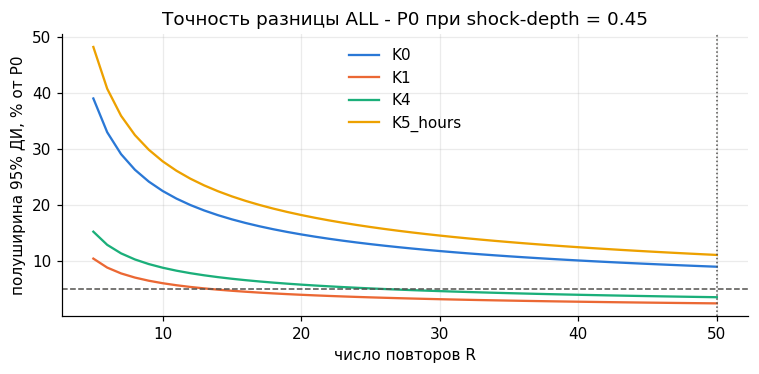

In [18]:
# Полуширина ДИ разницы ALL - P0 в % от среднего P0 как функция R (по дисперсии пилота)
Rs = np.arange(5, 51)
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, k in enumerate(["K0", "K1", "K4", "K5_hours"]):
    sd = (wide[(k, "ALL")] - wide[(k, "P0")]).std()
    m0 = wide[(k, "P0")].mean()
    if m0 > 0:
        ax.plot(Rs, 100 * stats.t.ppf(1 - ALPHA / 2, Rs - 1) * sd / np.sqrt(Rs) / m0, color=C[i], label=k)
ax.axhline(100 * DELTA, color="#52514e", lw=1, ls="--"); ax.axvline(R_SCREEN, color="#52514e", lw=1, ls=":")
ax.set_xlabel("число повторов R"); ax.set_ylabel("полуширина 95% ДИ, % от P0")
ax.set_title("Точность разницы ALL - P0 при shock-depth = 0.45"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Бюджет и выбор плана скрининга

Полный факториал 2⁵ = 32 комбинации против полуреплики 2⁵⁻¹ разрешения V (16 комбинаций, генератор E = ABCD; главные эффекты и все парные взаимодействия не смешаны между собой, смешаны только с взаимодействиями 3-го и 4-го порядка). Правило: **если полный факториал укладывается в бюджет времени скрининга, берём его** - он оценивает и тройные взаимодействия, а их в нелинейной модели с порогами исключать заранее нельзя. Числа для этапов 2-5 - ориентировочные, их уточним на своих этапах.

In [19]:
SCREEN_BUDGET_H = 4.0   # сколько часов готовы отдать скринингу

import itertools
full = np.array(list(itertools.product([-1, 1], repeat=5)))
half = full[full[:, 4] == full[:, 0] * full[:, 1] * full[:, 2] * full[:, 3]]   # E = ABCD
# проверка разрешения V: главные эффекты и 10 парных взаимодействий попарно ортогональны
X = np.column_stack([half] + [half[:, i] * half[:, j] for i, j in itertools.combinations(range(5), 2)])
check("2^(5-1): главные эффекты и парные взаимодействия не смешаны", np.allclose(X.T @ X, len(half) * np.eye(X.shape[1])))

nS = len(SHOCK_LEVELS)
plan = pd.DataFrame([
    {"этап": "1. скрининг, полный 2^5", "прогонов": 32 * nS * R_SCREEN},
    {"этап": "1. скрининг, 2^(5-1) V", "прогонов": 16 * nS * R_SCREEN},
    {"этап": "2. уровни: 4 семейства x 60 LHS x 10 seed", "прогонов": 4 * 60 * nS * 10},
    {"этап": "3. устойчивость: 9 стратегий x 100 LHS x 3 seed", "прогонов": 9 * 100 * nS * 3},
    {"этап": "5. проверка: 9 стратегий x 30 новых seed", "прогонов": 9 * nS * 30},
])
plan["часов"] = (plan["прогонов"] / RUNS_PER_HOUR).round(1)
SCREENING_DESIGN = "full" if plan.loc[0, "часов"] <= SCREEN_BUDGET_H else "half_resV"
print(f"Пропускная способность: {RUNS_PER_HOUR:.0f} прогонов/ч на {N_WORKERS} процессах")
print("Решение для скрининга:", "полный факториал 2^5" if SCREENING_DESIGN == "full" else "полуреплика 2^(5-1), разрешение V")
plan

PASS 2^(5-1): главные эффекты и парные взаимодействия не смешаны
Пропускная способность: 164 прогонов/ч на 1 процессах
Решение для скрининга: полуреплика 2^(5-1), разрешение V


,этап,прогонов,часов
0,"1. скрининг, полный 2^5",4800,29.2
1,"1. скрининг, 2^(5-1) V",2400,14.6
2,2. уровни: 4 семейства x 60 LHS x 10 seed,7200,43.8
3,3. устойчивость: 9 стратегий x 100 LHS x 3 seed,8100,49.3
4,5. проверка: 9 стратегий x 30 новых seed,810,4.9


## 6. Базовый прогон P0 - точка нормировки

Все меры выключены, номинальная неопределённость, три уровня шока, первые `R_SCREEN` seed скринингового пула. Эти же прогоны - угол факториального плана этапа 1, повторно их считать не нужно (совпадают `run_id`).

Нормировка (применяем на этапах 1-4): K0, K1, K4, K5 делим на среднее P0 при том же `shock-depth` (и той же точке неопределённости на этапе 3): 1 = как без вмешательства, 0 = ущерба нет. У P0 K2 = K3 = 0, поэтому их на P0 делить нельзя; их приводим к масштабу дефицита P0: K2 / (L4-subsidy · K0(P0)) и K3-volume / K0(P0), то есть «сколько субсидированного импорта / низкосортного бензина на литр несостоявшегося дефицита».

In [20]:
scr_seeds = SEEDS["screening"][:R_SCREEN]
base_jobs = [job(s, "P0", shock=sh, stage="screening") for sh in SHOCK_LEVELS for s in scr_seeds]
BASE = ar.run_batch(base_jobs, CFG, n_workers=N_WORKERS, link=link, out_csv=OUT_DIR / "baseline_P0.csv")

def ci(x):
    x = np.asarray(x, float)
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return pd.Series({"mean": x.mean(), "ci95": h, "min": x.min(), "max": x.max()})

cols = ["K0", "K1", "K4", "K5_hours", "K0@90", "price", "dry_share"]
BASE_SUMMARY = BASE.groupby("shock")[cols].apply(lambda g: g.apply(ci)).unstack().round(2)
BASE_SUMMARY.to_csv(OUT_DIR / "baseline_P0_summary.csv", encoding="utf-8-sig")
print("Потеря мощности рынка:", BASE.groupby("shock")["capacity_loss"].first().round(3).to_dict())
BASE_SUMMARY

12:31:15 150 прогонов в процессе ноутбука
12:31:48 2/150 готово | прошло 0.6 мин | осталось ~40.8 мин
12:32:34 5/150 готово | прошло 1.3 мин | осталось ~37.9 мин
12:33:16 8/150 готово | прошло 2.0 мин | осталось ~35.8 мин
12:33:48 10/150 готово | прошло 2.5 мин | осталось ~35.6 мин
12:34:23 12/150 готово | прошло 3.1 мин | осталось ~36.0 мин
12:34:57 14/150 готово | прошло 3.7 мин | осталось ~35.9 мин
12:35:28 16/150 готово | прошло 4.2 мин | осталось ~35.2 мин
12:36:09 19/150 готово | прошло 4.9 мин | осталось ~33.8 мин
12:36:40 21/150 готово | прошло 5.4 мин | осталось ~33.3 мин
12:37:13 23/150 готово | прошло 6.0 мин | осталось ~33.0 мин
12:37:54 25/150 готово | прошло 6.6 мин | осталось ~33.2 мин
12:38:35 28/150 готово | прошло 7.3 мин | осталось ~31.9 мин
12:39:09 31/150 готово | прошло 7.9 мин | осталось ~30.3 мин
12:39:47 34/150 готово | прошло 8.5 мин | осталось ~29.1 мин
12:40:25 37/150 готово | прошло 9.2 мин | осталось ~28.0 мин
12:41:06 40/150 готово | прошло 9.8 мин | оста

K0                                        K1                                            K4                                      K5_hours  \
            mean     ci95       min        max        mean      ci95        min         max         mean       ci95         min          max      mean   
shock                                                                                                                                                    
0.20      686.29   251.66      0.00    3928.60   371655.56   9374.01  303946.48   441999.21   2318516.89   76914.02  1784146.02   2990317.71  13987.16   
0.45    33613.51  2916.66  13485.95   58458.04   792371.35  13524.57  663881.71   886718.65   6614657.13  161035.87  5193800.55   7945306.80  14082.65   
0.70   110973.46  5632.81  64641.18  175950.39  1178458.98  20257.06  986716.36  1312207.69  12741524.65  388843.34  9503878.78  15595098.52  38300.27   

                                         K0@90                               price                   dry_share                    
           ci95       min        max      mean     ci95       min        max  mean  ci95   min   max      mean  ci95   min   max  
shock                                                                                                                             
0.20     530.03  11223.66   18010.34    452.55   174.80      0.00    2873.90  1.43  0.04  1.20  1.83      0.22  0.04  0.08  0.85  
0.45     893.70  10293.14   24064.51  22942.76  1682.79  11385.33   39296.13  2.31  0.18  1.47  3.76      0.68  0.09  0.22  1.00  
0.70   10910.06  13388.78  214178.02  80678.14  3648.11  54030.24  114926.97  3.45  0.25  2.05  5.00      0.76  0.06  0.38  1.00

## 7. Фиксация подготовки

Всё, что нужно следующим этапам и разделу Experimental design отчёта: версии, хэш модели, константы, seed, горизонт, R, процессы, решение о плане, итоги проверок. Следующие этапы читают `prep_summary.json` и проверяют, что хэш модели не изменился.

In [24]:
import importlib.metadata as im
def _pkg_version(name):
    try:
        return im.version(name)
    except im.PackageNotFoundError:
        return "unknown"

PREP = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "netlogo_version": NETLOGO_VERSION, "model_file": MODEL_PATH.name, "model_sha256": MODEL_SHA256,
    "python": sys.version.split()[0], "pynetlogo": _pkg_version("pynetlogo"),
    "horizon": HORIZON, "checkpoints": CHECKPOINTS, "shock_levels": SHOCK_LEVELS, "shock_mid": SHOCK_MID,
    "lever_on": LEVER_ON, "lever_ranges": LEVER_RANGES, "unc_ranges": UNC_RANGES, "c3_range": C3_RANGE,
    "interface_defaults": INTERFACE_DEFAULTS, "nominal_uncertain": NOMINAL_UNC, "constants": CONSTANTS,
    "master_seed": MASTER_SEED, "r_screen": R_SCREEN, "delta": DELTA,
    "n_workers": N_WORKERS, "runs_per_hour": RUNS_PER_HOUR, "screening_design": SCREENING_DESIGN,
    "checks": CHECKS,
}
def _json_default(obj):
    # NetLogo/JVM strings are not recognized as Python strings by json.dumps.
    if type(obj).__name__ == "String" or type(obj).__module__.startswith("java."):
        return str(obj)

    if isinstance(obj, np.generic):
        return obj.item()

    return float(obj)


def _json_default(obj):
    if isinstance(obj, (str, int, float, bool)) or obj is None:
        return obj

    type_name = f"{type(obj).__module__}.{type(obj).__name__}"

    # JPype/NetLogo Java strings
    if type(obj).__name__.lower().endswith("string") or "java.lang.String" in type_name:
        return str(obj)

    if isinstance(obj, np.generic):
        return obj.item()

    # Java numeric/boolean wrappers
    try:
        if "Boolean" in type_name:
            return bool(obj)
        if any(t in type_name for t in ("Byte", "Short", "Integer", "Long")):
            return int(obj)
        if any(t in type_name for t in ("Float", "Double")):
            return float(obj)
    except (TypeError, ValueError):
        pass

    return str(obj)


(OUT_DIR / "prep_summary.json").write_text(
    json.dumps(PREP, indent=1, ensure_ascii=False, default=_json_default),
    encoding="utf-8",
)
n_fail = sum(not c["ok"] for c in CHECKS.values())
print(f"Проверок: {len(CHECKS)}, не пройдено: {n_fail}")
print("Файлы:", sorted(p.name for p in OUT_DIR.iterdir()))

Проверок: 1, не пройдено: 0
Файлы: ['baseline_P0.csv', 'baseline_P0_summary.csv', 'factors.csv', 'pilot.csv', 'prep_summary.json', 'seeds.json', 'timing.csv']
